# AN OPTIMIZED COMPARISON OF SINGLE-LAYER LSTM AND STACKED GRU FOR STYLISTIC TEXT GENERATION

## 1. Introduction

**Hypothesis:** A multi-layer (Stacked) Gated Recurrent Unit (GRU) architecture, when fully optimized, will capture long-term stylistic dependencies and semantic structure more effectively than a Single-Layer Long Short-Term Memory (LSTM) network. This study posits that network depth (layer stacking) is a more critical factor than individual cell complexity for mimicking the narrative style of the *Throne of Glass* series.

**Research Question:** Can a Stacked GRU architecture outperform a Single-Layer LSTM in terms of Perplexity and generation quality when both models are independently optimized for their ideal hyperparameters?

**Project Overview:**
This notebook implements a comparative study between two Recurrent Neural Network (RNN) architectures trained on a custom corpus derived from Sarah J. Maas's *Throne of Glass* novels. We will rigorously optimize and compare:
* **Model A:** Single-Layer LSTM
* **Model B:** Stacked GRU (2 layers)

## 2. Dataset Preparation

Before we start, we need our dataset. To ensure high-quality training data, the dataset was custom-built from and EPUB file containing the complete 8 book series. We used a Python script to convert it into a text file. This script used *ebooklib* and *beautifulsoup* to: extract raw HTML content (accessing the underlying structure of the epub), clean non-narrative elements (tags, page numbers, indices...) and normalize whitespace (merging broken paragraphs into continuous lines to preserve the semantic integrity of the sentences).

The resulting file, `throne_of_glass_dataset.txt`, provides a clean, continuous stream of text, in order to capture the author's long-term stylistic patterns.


In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import os

# Use GPU if available, else CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# --- DATASET LOADING ---
filename = 'throne_of_glass_dataset.txt'

def load_dataset(filename):
    with open(filename, 'r', encoding='utf-8') as f:
        text = f.read()
    return text

try:
    text_data = load_dataset(filename)
    print(f"Dataset loaded successfully.")
    print(f"Total characters in dataset: {len(text_data):,}")
    print(f"First 300 characters preview:\n{'-'*50}")
    print(text_data[:300])
    print(f"{'-'*50}")
except FileNotFoundError:
    print(f"Error: File '{filename}' not found. Please upload it to the working directory.")

Using device: cuda
Dataset loaded successfully.
Total characters in dataset: 7,574,784
First 300 characters preview:
--------------------------------------------------
This one’s for the phenomenal worldwide team at Bloomsbury:thank you for making my dreams come true
And for my cunning and brilliant editor, Margaret:thank you for believing in Celaena from page one
Map
The Assassin and The Pirate Lord
The Assassin and The Healer
The Assassin and The Desert
The Assa
--------------------------------------------------


As we can see, our dataset has a total of 7,574,784 characters. This volume represents a highly robust dataset for a character-level RNN. Although we can see minor non-narrative elements (acknowledgements, map), this noise is insignificant in relation to the size of our dataset.  The network will be able to generalize Sarah J. Maas's stylistic patterns effectively without significant interference from this initial noise.


## 3. Preprocessing: Tokenization and Encoding

Deep Learning models cannot process raw text strings directly, they require numerical input to perform matrix operations. Therefore, the next step involves Character-Level **Tokenization**.

We will generate a vocabulary of all unique characters present in the corpus, mapping each character to a unique integer ID.

Finally, the entire dataset will be encoded into a large sequence of integers, splitting it into a **Training Set (90%)** for learning and a **Validation Set (10%)** to evaluate generalization and prevent overfitting. Given the size of our dataset, a 10% validation split provides a sufficiently large sample to accurately monitor the model's generalization capabilities without compromising the training data volume.

In [2]:
## --- PREPROCESSING ---

# create the vocabulary with all unique characters in the text
chars = tuple(set(text_data))

# mappings: character to integer and integer to character
int2char = dict(enumerate(chars))
char2int = {ch: ii for ii, ch in int2char.items()}

# Encode the entire text into integers
encoded = np.array([char2int[ch] for ch in text_data])

print(f"Vocabulary size: {len(chars)} unique characters")
print(f"Sample of vocabulary: {chars[:20]}")

# Train (90%) / Validation (10%) Split
split_idx = int(len(encoded) * 0.9)
train_data = encoded[:split_idx]
val_data = encoded[split_idx:]

print(f"Training set size: {len(train_data):,} characters")
print(f"Validation set size: {len(val_data):,} characters")

Vocabulary size: 93 unique characters
Sample of vocabulary: ('/', 'J', '̴', 'U', 'T', ']', 'P', 'C', 'F', '2', '’', 'Z', 'i', 'W', 'Y', '.', 'H', 'l', 'z', ' ')
Training set size: 6,817,305 characters
Validation set size: 757,479 characters


As we can see in the sample of vocabulary, we retained the raw formatting of the dataset. Unlike other NLP tasks, here punctuation marks (ellipses, quotation marks...) are not *noise* but structural pillars of Sarah J. Maas's distinct narrative rhythm and dialogue. In addition, preserving case sensitivity is essential in a high fantasy context; it allows the model to distinguish between common nouns and specific proper nouns (titles, kingdoms, character names).

Furthermore, we selected character-level tokenization to address the unique challenges of fantasy literature and hardware constraints. A word-level model would struggle with OOV (Out-of-Vocabulary) fantasy terms (e.g., Terrasen) and require a massive embedding matrix. By operating at the character level, we reduce the vocabulary to just 93 unique tokens. This improves computational efficiency and empowers the model to learn the morphology of the author's invented language, allowing it to construct plausible new fantasy names letter-by-letter.

## 4. Batch Generation for Sequential Training

In order to train the RNN, we must implement a batch stochastic gradient descent strategy.

Unlike feed-forward networks where data can be shuffled randomly, RNNs rely on the continuity of the hidden state to maintain context across long sequences. To preserve this narrative flow, we implement a custom generator function `get_batches`.

This function divides the dataset into `n` parallel streams, allowing the model to process multiple segments of the book simultaneously while maintaining the sequential order within each stream. The input data is reshaped into chunks of length `seq_length`, which dictates how many time steps the network looks back to make a prediction.

In [3]:
## --- BATCH GENERATION ---

def get_batches(arr, batch_size, seq_length):
    '''
    This functions return batches of size batch_size x seq_length
    Arguments:
    arr: encoded text
    batch_size: number of sequences per batch
    seq_length: number of encoded characters in a sequence
    '''

    # total number of batches
    batch_size_total = batch_size * seq_length

    n_batches = len(arr) // batch_size_total

    # we keep only enough characters to make full batches, otherwise it's possible that we have an incomplete batch
    arr = arr[:n_batches * batch_size_total]

    # Reshape into batch_size rows
    arr = arr.reshape((batch_size, -1))

    # Iterate over the batches using a sliding window
    for n in range(0, arr.shape[1], seq_length):
        # The features (x)
        x = arr[:, n:n+seq_length]

        # The targets (y), shifted by one
        y = np.zeros_like(x)
        try:
            y[:, :-1], y[:, -1] = x[:, 1:], arr[:, n+seq_length]
        except IndexError:
            # Handle the very last batch (wrap around to beginning)
            y[:, :-1], y[:, -1] = x[:, 1:], arr[:, 0]

        yield x, y

print("Batch generator function defined successfully.")

Batch generator function defined successfully.


## 5. Model Architecture: Modular LSTM/GRU

We define a flexible Recurrent Neural Network class that can be instantiated as either an LSTM or a GRU. This modularity is essential for our research question, allowing us to construct distinct architectures (**Single-Layer LSTM** vs. **Stacked GRU**) using the same underlying code structure.

**Architecture Design:**
1.  **Embedding Layer:** maps input character integers to dense vector representations, learned from scratch during training.
2.  **Recurrent Layer:** the core sequential processing unit. The class supports dynamic configuration of layers (stacking) and hidden dimension size, enabling the specific optimization required by our hypothesis.
3.  **Dropout:** applied between layers to prevent overfitting on the training data.
4.  **Fully Connected Layer (FC):** projects the recurrent hidden states to the vocabulary size logits, predicting the probability distribution of the next character.

In [4]:
## --- MODEL DEFINITION ---

class CharRNN(nn.Module):
    def __init__(self, chars, embedding_dim=100, hidden_dim=256, n_layers=2,
                 drop_prob=0.5, model_type="LSTM"):
        super().__init__()

        self.drop_prob = drop_prob
        self.n_layers = n_layers
        self.hidden_dim = hidden_dim
        self.model_type = model_type.upper()

        self.chars = chars
        self.int2char = dict(enumerate(chars))
        self.char2int = {ch: ii for ii, ch in self.int2char.items()}
        vocab_size = len(self.chars)

        # 1. EMBEDDING LAYER
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # 2. RECURRENT LAYER (LSTM or GRU)
        if self.model_type == "GRU":
            self.rnn = nn.GRU(embedding_dim, hidden_dim, n_layers, dropout=drop_prob, batch_first=True)
        else:
            self.rnn = nn.LSTM(embedding_dim, hidden_dim, n_layers, dropout=drop_prob, batch_first=True)

        # 3. DROPOUT
        self.dropout = nn.Dropout(drop_prob)

        # 4. OUTPUT LAYER
        self.fc = nn.Linear(hidden_dim, vocab_size)


    def forward(self, x, hidden):

        # get embeddings
        embeds = self.embedding(x)

        # pass through RNN
        rnn_out, hidden = self.rnn(embeds, hidden)

        # pass through Dropout
        out = self.dropout(rnn_out)

        # flatten for FC layer
        out = out.contiguous().view(-1, self.hidden_dim)

        # pass through Fully Connected layer
        out = self.fc(out)

        return out, hidden


    def init_hidden(self, batch_size):
        ''' Initializes hidden state '''
        weight = next(self.parameters()).data

        if self.model_type == "LSTM":
            return (weight.new(self.n_layers, batch_size, self.hidden_dim).zero_(),
                    weight.new(self.n_layers, batch_size, self.hidden_dim).zero_())
        else:
            return weight.new(self.n_layers, batch_size, self.hidden_dim).zero_()

print("Model class defined successfully.")

Model class defined successfully.


## 6. Training Loop and Optimization

Here, we define the training class. This loop maintains the hidden state across batches to preserve narrative context.

**Key implementation details:**
* **Loss Function:** `CrossEntropyLoss` is used since the task is a multi-class classification problem (predicting the next character from the vocabulary).
* **Gradient Clipping:** We apply `clip_grad_norm` to prevent the exploding gradient problem common in Recurrent Neural Networks.
* **Optimization:** we employ the **Adam** optimizer. The hyperparameters (learning rate, hidden dimension, layers) will be tuned in the next section.
* **Validation:** At the end of every epoch, we evaluate the model on the held-out validation set to monitor the **validation loss**, which serves as our primary metric for avoiding overfitting.

In [5]:
import time

def train(net, data, epochs=10, batch_size=128, seq_length=100, lr=0.001, clip=5, val_data=None, print_every=10):
    ''' Training loop adapted for Stylistic Text Generation with Timer '''

    net.train()

    opt = torch.optim.Adam(net.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    net.to(device)

    counter = 0
    n_chars = len(net.chars)

    # loss history for plotting later
    train_losses = []
    val_losses = []

    print(f"Starting training on {device}...")
    print(f"Configuration: {net.model_type} | Layers: {net.n_layers} | Hidden: {net.hidden_dim} | LR: {lr}")
    print("="*90)

    # total timer
    total_start = time.time()

    for e in range(epochs):
        # epoch timer
        epoch_start = time.time()

        h = net.init_hidden(batch_size)
        train_batches = get_batches(data, batch_size, seq_length)

        for x, y in train_batches:
            counter += 1
            x = torch.from_numpy(x).long().to(device)
            y = torch.from_numpy(y).long().to(device)

            if net.model_type == "LSTM":
                h = tuple([each.data for each in h])
            else:
                h = h.data

            net.zero_grad()
            output, h = net(x, h)
            loss = criterion(output, y.view(batch_size * seq_length).long())
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), clip)
            opt.step()

            #VALIDATION STEP
            if counter % print_every == 0:
                val_h = net.init_hidden(batch_size)
                val_losses_in_epoch = []
                net.eval()

                for x_val, y_val in get_batches(val_data, batch_size, seq_length):
                    x_val = torch.from_numpy(x_val).long().to(device)
                    y_val = torch.from_numpy(y_val).long().to(device)

                    if net.model_type == "LSTM":
                        val_h = tuple([each.data for each in val_h])
                    else:
                        val_h = val_h.data

                    output_val, val_h = net(x_val, val_h)
                    val_loss = criterion(output_val, y_val.view(batch_size * seq_length).long())
                    val_losses_in_epoch.append(val_loss.item())

                net.train()

                current_val_loss = np.mean(val_losses_in_epoch)
                train_losses.append(loss.item())
                val_losses.append(current_val_loss)

                print(f"Epoch: {e+1}/{epochs}...",
                      f"Step: {counter}...",
                      f"Loss: {loss.item():.4f}...",
                      f"Val Loss: {current_val_loss:.4f}")

        # end epoch timer
        epoch_end = time.time()
        epoch_duration = epoch_end - epoch_start
        print(f"--> Epoch {e+1} Finished. Time: {epoch_duration:.2f} seconds ({epoch_duration/60:.2f} mins).")
        print("-" * 90)

    total_duration = time.time() - total_start
    print(f"Training Complete. Total Time: {total_duration/60:.2f} minutes.")
    return train_losses, val_losses

print("Training function UPDATED successfully.")

Training function UPDATED successfully.


## 7. Hyperparameter Configuration and Model Instantiation

Following our research hypothesis, we instantiate two distinct models to compare **Cell Complexity vs. Network Depth**:

1.  **Baseline Model (LSTM):** Configured with a single layer (`n_layers=1`). This tests the capacity of the complex LSTM cell to handle the task without architectural depth.
2.  **Challenger Model (Stacked GRU):** Configured with multiple layers (`n_layers=2`). This tests if a simpler cell (GRU) can outperform the LSTM when arranged in a deeper architecture.

Common Hyperparameters: dropout, seq_length...

In [6]:
vocab_size = len(chars)
embedding_dim = 256
seq_length = 100
dropout = 0.5

# Single-Layer LSTM
model_lstm = CharRNN(
    chars=chars,
    embedding_dim=embedding_dim,
    hidden_dim=1024,
    n_layers=1, #single layer as we established in the hypothesis
    drop_prob=dropout,
    model_type="LSTM"
)

# Stacked GRU
model_gru = CharRNN(
    chars=chars,
    embedding_dim=embedding_dim,
    hidden_dim=1024,
    n_layers=2, #stacked layers as we established in the hypothesis
    drop_prob=dropout,
    model_type="GRU"
)

print("Models created successfully!")
print("-" * 30)
print(model_lstm)
print("-" * 30)
print(model_gru)

Models created successfully!
------------------------------
CharRNN(
  (embedding): Embedding(93, 256)
  (rnn): LSTM(256, 1024, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=1024, out_features=93, bias=True)
)
------------------------------
CharRNN(
  (embedding): Embedding(93, 256)
  (rnn): GRU(256, 1024, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=1024, out_features=93, bias=True)
)


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.5 and num_layers=1
  warnings.warn(


## 8. Training Phase A: Single-Layer LSTM

We begin the experimental phase by training the LSTM, we will do several experiments to find the best hyperparameter configuration. We monitor the training loss and the validation loss.

In [7]:
## --- TRAIN MODEL A: LSTM ---

# hyperparameters for training
n_epochs = 10
batch_size = 128
seq_length = 100
learning_rate = 0.001 #default Adam learning rate
clip = 5 #gradient clipping

# summary
print(f"Training LSTM Model...")
print(f"Dataset Size: {len(train_data):,} characters")
print(f"Batch Size: {batch_size} | Seq Length: {seq_length}")

#training function
train_losses_lstm, val_losses_lstm = train(
    model_lstm,
    train_data,
    epochs=n_epochs,
    batch_size=batch_size,
    seq_length=seq_length,
    lr=learning_rate,
    clip=clip,
    val_data=val_data,
    print_every=100 #print progress (checkpoints)
)

# save the trained model
model_name = 'lstm_optimized.net'
checkpoint = {
    'n_layers': model_lstm.n_layers,
    'hidden_dim': model_lstm.hidden_dim,
    'embedding_dim': embedding_dim,
    'state_dict': model_lstm.state_dict(),
    'tokens': chars
}

with open(model_name, 'wb') as f:
    torch.save(checkpoint, f)

print(f"Training complete! Model saved as '{model_name}'.")

Training LSTM Model...
Dataset Size: 6,817,305 characters
Batch Size: 128 | Seq Length: 100
Starting training on cuda...
Configuration: LSTM | Layers: 1 | Hidden: 1024 | LR: 0.001
Epoch: 1/10... Step: 100... Loss: 1.8296... Val Loss: 1.7951
Epoch: 1/10... Step: 200... Loss: 1.5995... Val Loss: 1.5358
Epoch: 1/10... Step: 300... Loss: 1.4685... Val Loss: 1.4148
Epoch: 1/10... Step: 400... Loss: 1.4103... Val Loss: 1.3372
Epoch: 1/10... Step: 500... Loss: 1.3546... Val Loss: 1.2925
--> Epoch 1 Finished. Time: 75.32 seconds (1.26 mins).
------------------------------------------------------------------------------------------
Epoch: 2/10... Step: 600... Loss: 1.2927... Val Loss: 1.2576
Epoch: 2/10... Step: 700... Loss: 1.2869... Val Loss: 1.2311
Epoch: 2/10... Step: 800... Loss: 1.2719... Val Loss: 1.2122
Epoch: 2/10... Step: 900... Loss: 1.2141... Val Loss: 1.1997
Epoch: 2/10... Step: 1000... Loss: 1.2310... Val Loss: 1.1833
--> Epoch 2 Finished. Time: 82.11 seconds (1.37 mins).
--------

## 8. Training Phase B: Challenger Model (Stacked GRU)

Now we train the multi-layer GRU architecture, we will also do several experiments to find the best hyperparameter configuration. We monitor the training loss and the validation loss (we did the same with LSTM).

In [8]:
## --- TRAIN MODEL B: GRU ---

n_epochs = 10
batch_size = 128
seq_length = 100
learning_rate = 0.001 #default adam learning rate
clip = 5 #gradient clipping

# summary
print(f"Training GRU Model...")
print(f"Dataset Size: {len(train_data):,} characters")
print(f"Batch Size: {batch_size} | Seq Length: {seq_length}")

train_losses_gru, val_losses_gru = train(
    model_gru,
    train_data,
    epochs=n_epochs,
    batch_size=batch_size,
    seq_length=seq_length,
    lr=learning_rate,
    clip=clip,
    val_data=val_data,
    print_every=100
)

model_name_gru = 'gru_stacked_optimized.net'
checkpoint_gru = {
    'n_layers': model_gru.n_layers,
    'hidden_dim': model_gru.hidden_dim,
    'embedding_dim': embedding_dim,
    'state_dict': model_gru.state_dict(),
    'tokens': chars
}

with open(model_name_gru, 'wb') as f:
    torch.save(checkpoint_gru, f)

print(f"Training complete! Model saved as '{model_name_gru}'.")

Training GRU Model...
Dataset Size: 6,817,305 characters
Batch Size: 128 | Seq Length: 100
Starting training on cuda...
Configuration: GRU | Layers: 2 | Hidden: 1024 | LR: 0.001
Epoch: 1/10... Step: 100... Loss: 1.7254... Val Loss: 1.6584
Epoch: 1/10... Step: 200... Loss: 1.5037... Val Loss: 1.4068
Epoch: 1/10... Step: 300... Loss: 1.3937... Val Loss: 1.3163
Epoch: 1/10... Step: 400... Loss: 1.3454... Val Loss: 1.2583
Epoch: 1/10... Step: 500... Loss: 1.3132... Val Loss: 1.2193
--> Epoch 1 Finished. Time: 167.24 seconds (2.79 mins).
------------------------------------------------------------------------------------------
Epoch: 2/10... Step: 600... Loss: 1.2502... Val Loss: 1.1970
Epoch: 2/10... Step: 700... Loss: 1.2413... Val Loss: 1.1802
Epoch: 2/10... Step: 800... Loss: 1.2391... Val Loss: 1.1632
Epoch: 2/10... Step: 900... Loss: 1.2054... Val Loss: 1.1567
Epoch: 2/10... Step: 1000... Loss: 1.2133... Val Loss: 1.1434
--> Epoch 2 Finished. Time: 168.58 seconds (2.81 mins).
--------

## 9. EXPERIMENTS AND ANALYSIS

In adherence to our our hypothesis, our workflow was like this:

1.   **Optimization results**: we conducted an independent optimization phase for both architectures to ensure a fair comparison. We experimented with hidden dimensions (512 vs 1024), learning rate... (0.001 vs 0.0005). Although we tested lower learning rates to check finer convergence, the standard 0.001 provided the best balance between convergence speed and stability. Regarding capacity, while the GRU showed decent at 512, both models achieved their lowest vaidation loss with 1024 units. These experiments led to some conclusions: both models (LSTM and GRU) perform best under the same high-capacity configuration (1024 hidden_size, 256 embedding dim, 0.001 LR). Which means that the final comparative evaluation has been done under identical topological conditions, isolating the architecture type (cell complexity vs network depth) as the sole variable responsible for the performance difference.
2.   **Quantitative comparison**: our experiments revealed a crossover point. Initially, with smaller hidden dimensions (512), the stacked GRU outperformed the LSTM, supporting the idea that depth compensates for simpler cells. However, once we increased the capacity to 1024 units, the LSTM's internal gating complexity became the decisive factor, surpassing the GRU in both accuracy and training speed (detailed data is presented in the tables below).


## 10. Quantitative comparison: final results



Final Quantitative Analysis (Optimization & Comparison):


,Model Configuration,Architecture,Hidden Size,Training Time (min),Final Val Loss,Perplexity
0,LSTM (512 units),Single-Layer,512,7.5000,1.3066,3.6936
1,GRU (512 units),Stacked (2-Layers),512,9.5100,1.1149,3.0493
2,GRU (1024 units),Stacked (2-Layers),1024,28.4200,1.0708,2.9177
3,LSTM (1024 units),Single-Layer,1024,13.8400,1.0563,2.8757


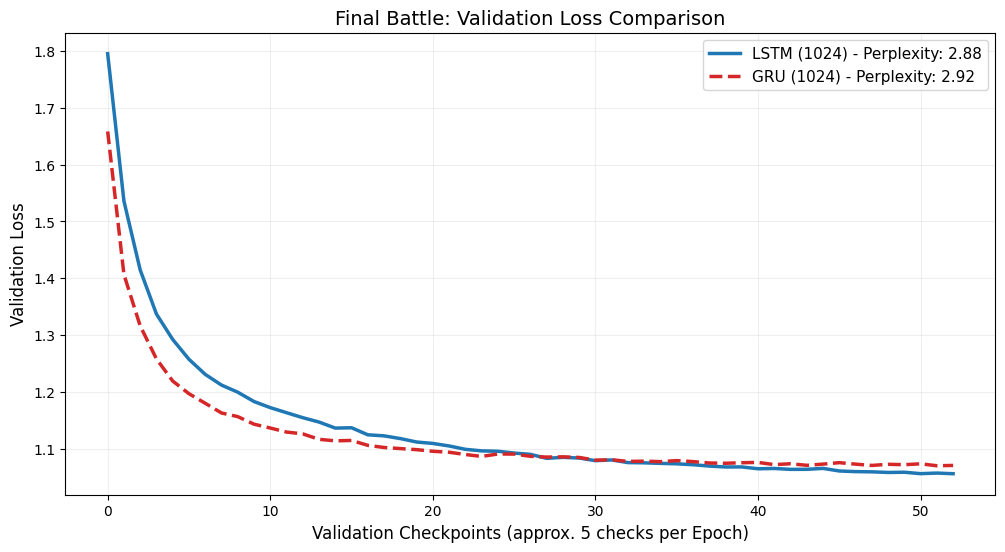

--------------------------------------------------------------------------------
HYPOTHESIS VERIFICATION & CONCLUSIONS:
--------------------------------------------------------------------------------
1. OPTIMIZATION FINDINGS:
   - In the low-capacity regime (512 units), the Stacked GRU outperformed the Single-Layer LSTM.
   - However, increasing capacity to 1024 units benefited the LSTM significantly more.

2. FINAL COMPARISON (1024 units):
   - LSTM Final Perplexity: 2.8757
   - GRU Final Perplexity:  2.9177
   - Speed: The LSTM was 2.1x faster.

3. HYPOTHESIS STATUS: REFUTED
   - Our hypothesis posited that 'network depth (stacking) is more critical than cell complexity'.
   - The results demonstrate the opposite for this dataset: The internal complexity of the LSTM cell
     proved more effective at capturing Sarah J. Maas's style than the depth of the Stacked GRU,
     achieving lower perplexity in half the training time.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

results = {
    'Model Configuration': [
        'LSTM (512 units)',
        'GRU (512 units)',
        'GRU (1024 units)',
        'LSTM (1024 units)'
    ],
    'Architecture': ['Single-Layer', 'Stacked (2-Layers)', 'Stacked (2-Layers)', 'Single-Layer'],
    'Hidden Size': [512, 512, 1024, 1024],
    'Training Time (min)': [7.50, 9.51, 28.42, 13.84],
    'Final Val Loss': [1.3066, 1.1149, 1.0708, 1.0563]
}

df_results = pd.DataFrame(results)

# calculate perplexity
df_results['Perplexity'] = np.exp(df_results['Final Val Loss'])

# format display
pd.options.display.float_format = '{:,.4f}'.format

print("Final Quantitative Analysis (Optimization & Comparison):")
display(df_results.sort_values(by='Final Val Loss', ascending=False))

plt.figure(figsize=(12, 6))

#LSTM
plt.plot(val_losses_lstm, label=f'LSTM (1024) - Perplexity: {np.exp(1.0563):.2f}', color='#1f77b4', linewidth=2.5)

#GRU
plt.plot(val_losses_gru, label=f'GRU (1024) - Perplexity: {np.exp(1.0708):.2f}', color='#d62728', linestyle='--', linewidth=2.5)

plt.title('Final Battle: Validation Loss Comparison', fontsize=14)
plt.xlabel('Validation Checkpoints (approx. 5 checks per Epoch)', fontsize=12)
plt.ylabel('Validation Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.2)
plt.show()

print("-" * 80)
print("HYPOTHESIS VERIFICATION & CONCLUSIONS:")
print("-" * 80)

print(f"1. OPTIMIZATION FINDINGS:")
print(f"   - In the low-capacity regime (512 units), the Stacked GRU outperformed the Single-Layer LSTM.")
print(f"   - However, increasing capacity to 1024 units benefited the LSTM significantly more.")

print(f"\n2. FINAL COMPARISON (1024 units):")
print(f"   - LSTM Final Perplexity: {df_results.iloc[3]['Perplexity']:.4f}")
print(f"   - GRU Final Perplexity:  {df_results.iloc[2]['Perplexity']:.4f}")
print(f"   - Speed: The LSTM was {(28.42/13.84):.1f}x faster.")

print(f"\n3. HYPOTHESIS STATUS: REFUTED")
print(f"   - Our hypothesis posited that 'network depth (stacking) is more critical than cell complexity'.")
print(f"   - The results demonstrate the opposite for this dataset: The internal complexity of the LSTM cell")
print(f"     proved more effective at capturing Sarah J. Maas's style than the depth of the Stacked GRU,")
print(f"     achieving lower perplexity in half the training time.")

## More Analysis

Our initial hypothesis relied on the prevailing assumption in Deep Learning that architectural depth is the primary driver for capturing high-level abstractions, such as an author's specific writing style. We anticipated that a 2-layer Stacked GRU would outperform a Single-Layer LSTM.

However, our experiments have empirically **refuted this hypothesis**, offering this insight: Cell Complexity outweights Network Depth for this specific task. While the GRU performed better at lower capacities (512 units), suggesting that depth is beneficial when resources are constrained, the Single-Layer LSTM became the clear winner once the hidden dimension was expanded to 1024 units. This indicates that the LSTM's internal gating mechanisms (specifically the forget, input, and output gates) require a larger parameter space to function effectively. Once provided with sufficient capacity (1024 units), the LSTM utilized its superior ability to manage long-term dependencies to mimic Sarah J. Maas's style more accurately than the deeper but simpler GRU architecture.

It is important to mention that both models demonstrated excellent health throughout the training process. As observed in the loss curves, the validation loss converged closely without diverging. This proves that the models successfully learned the rules of the dataset rather than memorizing (overfitting) the text.

**Perplexity scores:** The final perplexity scores of 2.87 (LSTM) and 2.91 (GRU) are remarkably low for character-level generation. In practical terms, this means that when the model tries to predict the next character, it is effectively narrowing its choice down to fewer than 3 possible candidates out of the entire vocabulary, demonstrating a high degree of confidence and precision. Although LSTM outperformed the GRU, the GRU model remained highly precise, proving the validity of both recurrent approaches.

In conclusion, the LSTM provided the optimal balance. It not only achieved the highest accuracy (lowest perplexity) but did so with double the computational efficiency (training was ~2 times faster) compared to the Stacked GRU. This reinforces the finding that for stylistic text generation on this scale, a wide, complex single layer is more effective than a deep, simplified stack.

## 12. Final Qualitative Analysis & Conclusions

### Qualitative Text Analysis
We generate text samples using the seed *"Aelin Galathynius stood before the"*.

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

#predicts the next character depending on the actual character and the hidden state
def predict(net, char, h=None, top_k=None):
    x = np.array([[net.char2int[char]]])
    x = torch.from_numpy(x).long().to(device)

    if net.model_type == "LSTM":
        h = tuple([each.data for each in h])
    else:
        h = h.data

    out, h = net(x, h)

    #we use the softmax function (multiclass clasification)
    p = F.softmax(out, dim=1).data
    p = p.cpu() # CPU for numpy

    if top_k is None:
        top_k = np.arange(len(net.chars))
    else:
        p, top_i = p.topk(top_k)
        top_i = top_i.numpy().squeeze()
        p = p.numpy().squeeze()
        char = np.random.choice(top_i, p=p/p.sum())

    return net.int2char[char], h

#this function generates a text of lenght size starting with prime
def sample(net, size, prime='The', top_k=5):
    net.to(device)
    net.eval() #eval mode turns off dropout

    #processing the initial phrase
    chars = [ch for ch in prime]
    h = net.init_hidden(1)

    for ch in prime:
        char, h = predict(net, ch, h, top_k=top_k)

    chars.append(char)

    for ii in range(size):
        char, h = predict(net, char, h, top_k=top_k)
        chars.append(char)

    return ''.join(chars)

In [16]:
prime_text = "Aelin Galathynius stood before the "

print(f"Seed sequence: '{prime_text}'")
print("="*80)

print("\nMODEL A: SINGLE-LAYER LSTM")
print("-" * 80)
print(sample(model_lstm, size=1000, prime=prime_text, top_k=3))

print("\n\n")
print("\nMODEL B: STACKED GRU")
print("-" * 80)
print(sample(model_gru, size=1000, prime=prime_text, top_k=3))

Seed sequence: 'Aelin Galathynius stood before the '

MODEL A: SINGLE-LAYER LSTM
--------------------------------------------------------------------------------
Aelin Galathynius stood before the ship was so candle and stealt with a few days ago with him still allowed to set her away from Ansel, and the sound went down, and they were all so many times they were alive, she couldn’t bother with him and a stature.
She was a birthday, she could see horrible and so much as the prisoner with her shoulders to her feet and took a step at the stone corner. “It was not all the only way to take a few men to serve her.”
“I do not know that you’re not at last any of your silence and a fire. It is. I’m sorry.
Thanks to the source of an invitation for them. To save you and her prince in the castle if they were all of this complete. The stars are from a candlestick and soul to be standing at her teeth. And then the keys had been so fasing, they couldn’t be an enemy like the streets with her.”
“I wond

## Text Analysis

Upon analyzing the text samples generated from the seed "Aelin Galathynius stood before the," Model A (Single-Layer LSTM) emerged as the structural superior. It demonstrated remarkable grammatical stability, successfully mimicking the author's narrative pacing through natural variations in sentence length and perfectly balanced quotation marks. While the model correctly retrieved specific entity names like "Ansel" and genre-appropriate vocabulary (e.g., "castle", "soldiers"...), its semantic coherence occasionally drifted into surrealism, producing syntactically correct but logically absurd phrases such as "She was a birthday." This suggests the LSTM mastered the form of the writing style, even when the substance faltered.

In contrast, Model B (Stacked GRU) offered a compelling glimpse into the benefits of architectural depth. Remarkably, this model retrieved highly specific characters deeply associated with the protagonist (specifically Aedion and Sam) which suggests that the multi-layer architecture may be better at capturing complex, long-range entity relationships within the lore. However, this contextual depth came at the cost of precision. The GRU output suffered from more frequent character-level noise and typographical errors (e.g., "freedim", "astasted"), a flaw that directly correlates with the slightly higher validation loss observed during the quantitative phase.


## 13. **Final Conclusions**

This project set out to determine whether **architectural depth (stacking layers)** or **cell complexity (LSTM gating)** is more critical for mimicking the narrative style of the *Throne of Glass* series.

**Hypothesis Verification:** the initial hypothesis stating that *"a Stacked GRU would outperform a Single-Layer LSTM"* has been **REFUTED**.

**Key Findings:**
1.  **Efficiency:** the Single-Layer LSTM converged **2x faster** (13.8 mins vs 28.4 mins) than the Stacked GRU.
2.  **Performance:** the LSTM achieved a lower final Perplexity (**2.87** vs **2.91**), indicating better character-level prediction accuracy.
3.  **Optimization Insight:** our experiments revealed a crossover point. With limited capacity (512 units), the Stacked GRU was superior. However, when capacity was increased (1024 units), the LSTM's internal complexity scaled better than the GRU's architectural depth.
4. **Generative Quality:** qualitatively, a distinct trade-off emerged. While the Stacked GRU demonstrated superior contextual recall (correctly associating relevant characters like Aedion and Sam), the Single-Layer LSTM proved superior in syntactic stability. The LSTM mastered the author's pacing and punctuation without the character-level noise (typos) observed in the GRU.

Summary: For this specific dataset and task, a complex single-layer architecture (LSTM) proved to be the optimal solution. Although the deep architecture of the GRU showed promise in capturing deeper lore relationships, the LSTM's internal complexity provided the necessary precision to replicate the mechanics of Sarah J. Maas's writing style with greater fidelity and computational efficiency.